# Ridgeline Infrastructure — Análisis exploratorio y control de valor ganado (EVM)

**Objetivo:** entender por qué los proyectos de Ridgeline terminan sobre presupuesto y fuera de plazo, medir qué tan temprano se puede ver el problema y revisar el estado de los proyectos activos y de la flota de equipos.

> **Sobre los datos.** Ridgeline es una empresa **ficticia** y los datos son **sintéticos** (`src/generate_data.py`). Los patrones se diseñaron para poder demostrar el método, y las curvas de costo son más limpias que las de una obra real. Por eso las cifras de este notebook ilustran el **proceso de análisis**; no son referencias de desempeño del sector.

**Contenido**
1. Calidad de los datos
2. Resultados del portafolio: sobrecosto y atraso
3. Valor ganado (CPI, SPI, EAC) y alerta temprana
4. Estado de los proyectos activos
5. Otros factores: órdenes de cambio y lluvia
6. Precios ofertados vs. reales
7. Flota: ralentí y firma de falla
8. Hallazgos y siguientes pasos

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../src")
import viz
from viz import ACCENT, DEEMPH, INK, INK2, MUTED, SURFACE, STATUS
viz.setup()          # tipografía, paleta y estilo compartidos (src/viz.py)

DATA = Path("../data")
projects = pd.read_csv(DATA/"projects.csv", parse_dates=["start_date", "planned_end", "actual_end"])
evm      = pd.read_csv(DATA/"weekly_evm.csv", parse_dates=["week_ending"])
bids     = pd.read_csv(DATA/"bid_items.csv")
cos      = pd.read_csv(DATA/"change_orders.csv", parse_dates=["date"])
tele     = pd.read_csv(DATA/"equipment_telemetry.csv", parse_dates=["date"])
fails    = pd.read_csv(DATA/"equipment_failures.csv", parse_dates=["failure_date"])

{n: len(d) for n, d in dict(projects=projects, evm=evm, bids=bids, change_orders=cos, telemetry=tele, failures=fails).items()}

{'projects': 38, 'evm': 1568, 'bids': 230, 'change_orders': 86, 'telemetry': 13482, 'failures': 5}

## 1. Calidad de los datos

Antes de analizar, se comprueba que las tablas sean coherentes entre sí.

In [2]:
bac = projects.set_index("project_id").budget_at_completion
checks = {
    "IDs de proyecto únicos": projects.project_id.is_unique,
    "Sin nulos en la serie EVM": not evm.isna().any().any(),
    "EV acumulado nunca decrece": bool(evm.groupby("project_id").earned_value.apply(lambda s: s.is_monotonic_increasing).all()),
    "EV nunca supera el BAC": bool((evm.earned_value <= evm.project_id.map(bac) * 1.001).all()),
    "Proyectos completados tienen costo final": bool(projects.query("status == 'Completed'").final_cost.notna().all()),
    "Proyectos activos sin fecha de fin": bool(projects.query("status == 'Active'").actual_end.isna().all()),
}
pd.Series(checks, name="OK")

,OK
IDs de proyecto únicos,True
Sin nulos en la serie EVM,True
EV acumulado nunca decrece,True
EV nunca supera el BAC,True
Proyectos completados tienen costo final,True
Proyectos activos sin fecha de fin,True


Las seis comprobaciones pasan: no hay duplicados ni nulos, el valor ganado es creciente y nunca excede el presupuesto.

## 2. Resultados del portafolio: sobrecosto y atraso

Se calculan para los **35 proyectos completados**: sobrecosto = costo final / presupuesto − 1; atraso = duración real / duración planificada − 1.

In [3]:
done = projects[projects.status == "Completed"].copy()
done["overrun_pct"]   = (done.final_cost / done.budget_at_completion - 1) * 100
done["planned_weeks"] = (done.planned_end - done.start_date).dt.days / 7
done["actual_weeks"]  = (done.actual_end  - done.start_date).dt.days / 7
done["delay_pct"]     = (done.actual_weeks / done.planned_weeks - 1) * 100
done["start_year"]    = done.start_date.dt.year
done["co_pct"]        = done.change_order_total / done.budget_at_completion * 100

portfolio = pd.Series({
    "Proyectos completados": len(done),
    "Presupuesto total (USD M)": round(done.budget_at_completion.sum() / 1e6, 1),
    "Costo final total (USD M)": round(done.final_cost.sum() / 1e6, 1),
    "Sobrecosto agregado (USD M)": round((done.final_cost.sum() - done.budget_at_completion.sum()) / 1e6, 1),
    "Sobrecosto agregado (%)": round((done.final_cost.sum() / done.budget_at_completion.sum() - 1) * 100, 1),
    "Proyectos con sobrecosto > 10 %": int((done.overrun_pct > 10).sum()),
    "Proyectos con sobrecosto > 20 %": int((done.overrun_pct > 20).sum()),
    "Proyectos con atraso > 10 %": int((done.delay_pct > 10).sum()),
}, name="Portafolio")
portfolio

,Portafolio
Proyectos completados,35.0
Presupuesto total (USD M),228.3
Costo final total (USD M),266.2
Sobrecosto agregado (USD M),37.8
Sobrecosto agregado (%),16.6
Proyectos con sobrecosto > 10 %,21.0
Proyectos con sobrecosto > 20 %,9.0
Proyectos con atraso > 10 %,23.0


In [4]:
def summary(by):
    g = done.groupby(by)
    return pd.DataFrame({
        "n": g.size(),
        "sobrecosto_medio_%": g.overrun_pct.mean().round(1),
        "atraso_medio_%": g.delay_pct.mean().round(1),
        "sobrecosto_USD_M": ((g.final_cost.sum() - g.budget_at_completion.sum()) / 1e6).round(1),
    })

by_type, by_pm, by_year = summary("type"), summary("project_manager"), summary("start_year")
by_type.sort_values("sobrecosto_medio_%", ascending=False)

,n,sobrecosto_medio_%,atraso_medio_%,sobrecosto_USD_M
type,,,,
New bridge,1,26.2,39.0,8.2
Intersection upgrade,7,17.4,15.6,9.8
Road resurfacing,10,15.2,8.2,7.4
Drainage & culverts,13,13.3,11.3,8.0
Bridge rehabilitation,4,10.3,26.0,4.5


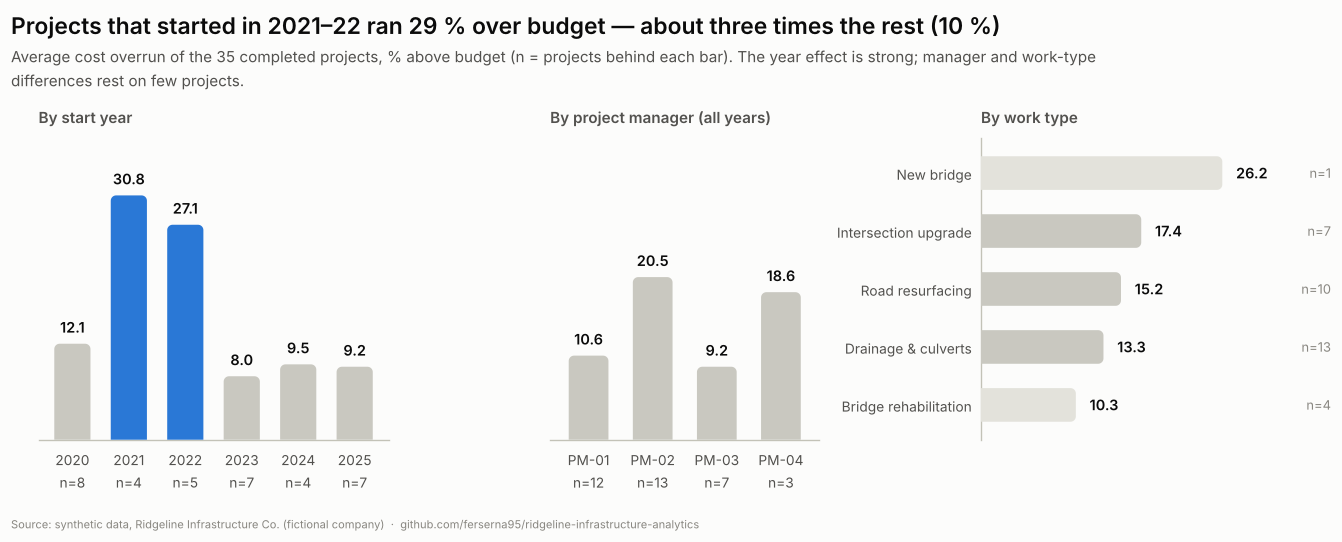

In [5]:
crisis_years = (2021, 2022)
hi = done[done.start_year.isin(crisis_years)].overrun_pct.mean()
lo = done[~done.start_year.isin(crisis_years)].overrun_pct.mean()

fig, gs = viz.new_fig(12.6, 5.1,
    f"Projects that started in 2021–22 ran {hi:.0f} % over budget — about three times the rest ({lo:.0f} %)",
    "Average cost overrun of the 35 completed projects, % above budget (n = projects behind each bar). "
    "The year effect is strong; manager and work-type differences rest on few projects.",
    ncols=3, width_ratios=[1.3, 1.0, 1.3], wspace=0.5, bottom=1.0)
ax_y, ax_pm, ax_t = (fig.add_subplot(gs[0, i]) for i in range(3))

def column_panel(ax, df, title, colors, ymax=38):
    vals = df["sobrecosto_medio_%"].values
    ax.set_xlim(-0.6, len(vals) - 0.4); ax.set_ylim(0, ymax)
    viz.style_axes(ax, grid=None, panel_title=title); ax.set_yticks([])
    viz.bars(ax, range(len(vals)), vals, colors, thick=26)
    for i, v in enumerate(vals):
        viz.label(ax, i, v, f"{v:.1f}", ha="center", va="bottom", dy=5, weight="semibold")
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels([f"{i}\nn={int(n)}" for i, n in zip(df.index, df.n)], color=INK2, fontsize=9, linespacing=1.35)

column_panel(ax_y, by_year, "By start year", [ACCENT if y in crisis_years else DEEMPH for y in by_year.index])
column_panel(ax_pm, by_pm, "By project manager (all years)", DEEMPH)

# panel 3 - by work type (horizontal, sorted)
t = by_type.sort_values("sobrecosto_medio_%")
ax_t.set_xlim(0, 38); ax_t.set_ylim(-0.6, len(t) - 0.4)
viz.style_axes(ax_t, grid=None, baseline="left", panel_title="By work type"); ax_t.set_xticks([])
viz.bars(ax_t, range(len(t)), t["sobrecosto_medio_%"].values, ["#e3e2db" if n < 7 else DEEMPH for n in t.n], orient="h", thick=22)
for i, (v, n) in enumerate(zip(t["sobrecosto_medio_%"], t.n)):
    viz.label(ax_t, v, i, f"{v:.1f}", dx=9, weight="semibold")
    viz.label(ax_t, 38, i, f"n={int(n)}", ha="right", color=MUTED, size=8.5)
ax_t.set_yticks(range(len(t))); ax_t.set_yticklabels(t.index, color=INK2, fontsize=9)
viz.save(fig, "01_overrun_drivers")

**Lectura con cuidado**
- **Tipo de obra:** las diferencias entre repavimentación, drenaje e intersecciones (13–17 %) son pequeñas. Los puentes parecen peores en atraso (26 % y 39 %), pero **solo hay 5 proyectos de puentes** y el puente nuevo es **un único caso**. Con esa muestra no se puede concluir nada sobre este tipo de obra.
- **Año de inicio:** es el corte más claro. Las obras que empezaron en **2021–2022 terminaron con ~29 % de sobrecosto**, frente a ~10 % del resto.
- **Gerente de proyecto:** PM-02 aparece con 20.5 %, pero dirigió 6 de los 9 proyectos de 2021–2022. Antes de atribuirle el resultado hay que **controlar por año** (siguiente celda).

In [6]:
done["crisis"] = np.where(done.start_year.isin([2021, 2022]), "2021–22", "otros años")
ctrl = (done.groupby(["crisis", "project_manager"]).agg(n=("overrun_pct", "size"),
        sobrecosto_medio=("overrun_pct", "mean"), atraso_medio=("delay_pct", "mean")).round(1))
print("Resumen por periodo:")
print(done.groupby("crisis").agg(n=("overrun_pct", "size"), sobrecosto_medio=("overrun_pct", "mean"),
                                 atraso_medio=("delay_pct", "mean")).round(1).to_string())
ctrl

Resumen por periodo:
             n  sobrecosto_medio  atraso_medio
crisis                                        
2021–22      9              28.8          10.9
otros años  26               9.8          14.8


n  sobrecosto_medio  atraso_medio
crisis     project_manager                                    
2021–22    PM-01             2              25.5           5.3
           PM-02             6              30.0          14.0
           PM-03             1              27.9           3.6
otros años PM-01            10               7.7          11.1
           PM-02             7              12.3          18.7
           PM-03             6               6.1          11.4
           PM-04             3              18.6          24.4

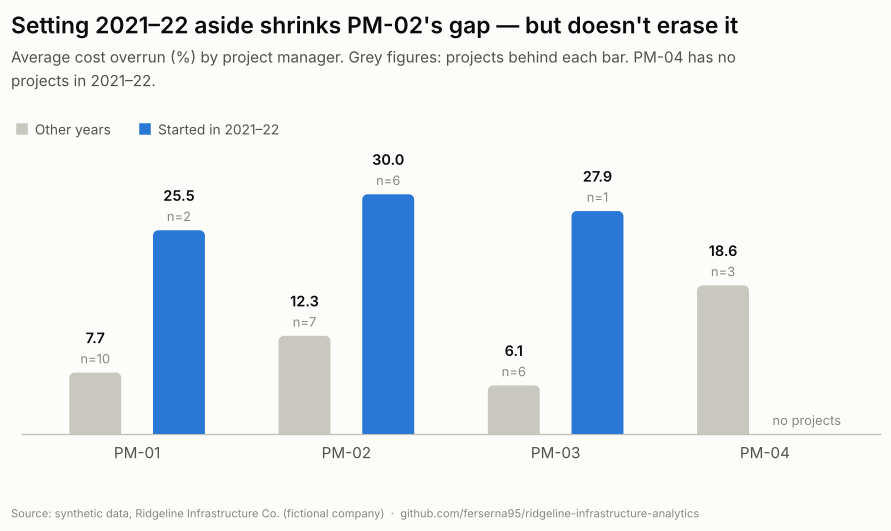

In [7]:
piv = ctrl.sobrecosto_medio.unstack("crisis")[["otros años", "2021–22"]]
cnt = ctrl.n.unstack("crisis").reindex(piv.index).fillna(0)

fig, gs = viz.new_fig(8.6, 5.0,
    "Setting 2021–22 aside shrinks PM-02's gap — but doesn't erase it",
    "Average cost overrun (%) by project manager. Grey figures: projects behind each bar. PM-04 has no projects in 2021–22.",
    left=0.4, right=0.4, bottom=0.95)
ax = fig.add_subplot(gs[0, 0])
ax.set_xlim(-0.55, len(piv) - 0.45); ax.set_ylim(0, 37)
viz.style_axes(ax, grid=None); ax.set_yticks([])
x = np.arange(len(piv)); off = 0.2
for col, color, o in (("otros años", DEEMPH, -off), ("2021–22", ACCENT, off)):
    viz.bars(ax, x + o, piv[col].values, color, thick=34)
    for xi, v, k in zip(x + o, piv[col].values, cnt[col].values):
        if k > 0:
            viz.label(ax, xi, v, f"{v:.1f}", ha="center", va="bottom", dy=17, weight="semibold")
            viz.label(ax, xi, v, f"n={int(k)}", ha="center", va="bottom", dy=4, color=MUTED, size=8.5)
        else:
            viz.label(ax, xi, 0, "no projects", ha="center", va="bottom", dy=4, color=MUTED, size=8.5)
ax.set_xticks(x); ax.set_xticklabels(piv.index, color=INK2, fontsize=10)
viz.legend_keys(ax, [("Other years", DEEMPH), ("Started in 2021–22", ACCENT)], loc=(0.0, 1.03))
viz.save(fig, "01b_pm_controlled_for_year")

**Conclusión de este corte**
- En 2021–22 los tres gerentes con proyectos en ese periodo (con solo 2, 6 y 1 proyectos respectivamente) terminaron entre 25 y 30 %: el problema fue de mercado, no de una persona.
- Fuera de ese periodo, PM-02 (12.3 %) sigue por encima de PM-01 (7.7 %) y PM-03 (6.1 %): hay una diferencia real, aunque **mucho menor** que la que mostraba el primer gráfico (20.5 % vs. ~10 %).
- PM-04 muestra 18.6 % de sobrecosto y 24 % de atraso, pero con **solo 3 proyectos**. Es una señal para vigilar, no una conclusión.

Los puntos 2021–22 y los gerentes se retoman al final. Primero, la pregunta de fondo: **¿cuándo se puede ver el problema?**

## 3. Valor ganado (EVM): CPI, SPI y alerta temprana

Con la serie semanal de cada proyecto se calculan:

| Métrica | Fórmula | Lectura |
|---|---|---|
| **% de avance** | EV / BAC | cuánto del trabajo presupuestado está hecho |
| **CPI** | EV / AC | eficiencia de costo; < 1 significa que cada dólar gastado rinde menos de un dólar de trabajo |
| **SPI** | EV / PV | eficiencia de cronograma; < 1 significa atraso |
| **EAC** | BAC / CPI | costo final estimado si el rendimiento actual se mantiene |

In [8]:
evm = evm.merge(projects[["project_id", "budget_at_completion"]], on="project_id")
evm["pct_complete"] = evm.earned_value / evm.budget_at_completion
evm["CPI"] = evm.earned_value / evm.actual_cost          # eficiencia de costo: < 1 = sobrecosto
evm["SPI"] = evm.earned_value / evm.planned_value        # eficiencia de cronograma: < 1 = atraso
evm["EAC"] = evm.budget_at_completion / evm.CPI          # costo final estimado
evm[["project_id", "week", "pct_complete", "CPI", "SPI", "EAC"]].tail(3).round(3)

,project_id,week,pct_complete,CPI,SPI,EAC
1565,P038,27,0.978,0.832,0.978,6818370.331
1566,P038,28,0.990,0.829,0.990,6842606.853
1567,P038,29,0.997,0.839,0.997,6758067.899


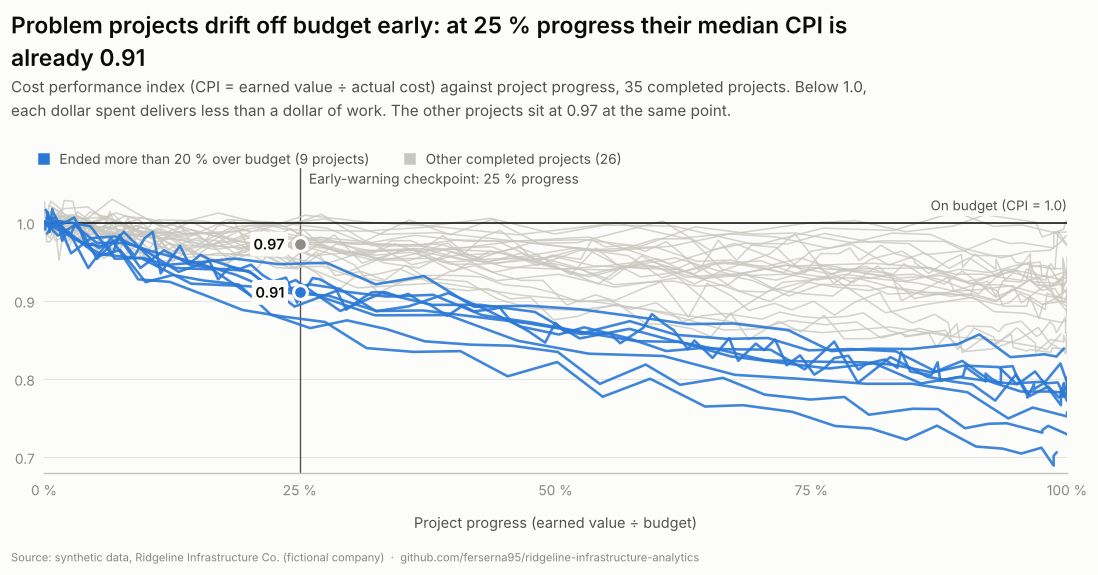

In [9]:
cpi25 = pd.Series({pid: g[g.pct_complete >= 0.25].iloc[0].CPI
                   for pid, g in evm[evm.project_id.isin(done.project_id)].groupby("project_id")})
prob = done.set_index("project_id").overrun_pct > 20
med_p, med_o = cpi25[prob].median(), cpi25[~prob].median()

fig, gs = viz.new_fig(10.4, 5.4,
    f"Problem projects drift off budget early: at 25 % progress their median CPI is already {med_p:.2f}",
    f"Cost performance index (CPI = earned value ÷ actual cost) against project progress, 35 completed projects. "
    f"Below 1.0, each dollar spent delivers less than a dollar of work. The other projects sit at {med_o:.2f} at the same point.",
    left=0.6, right=0.5, bottom=1.0)
ax = fig.add_subplot(gs[0, 0])
ax.set_xlim(0, 100); ax.set_ylim(0.68, 1.07)
viz.style_axes(ax, grid="y")
for is_prob, color, lw, z in ((False, DEEMPH, 1.0, 2), (True, ACCENT, 1.7, 3)):
    for pid, g in evm[evm.project_id.isin(done.project_id)].groupby("project_id"):
        if bool(prob[pid]) == is_prob:
            ax.plot(g.pct_complete * 100, g.CPI, color=color, lw=lw, alpha=0.9 if is_prob else 0.8, zorder=z)

viz.hline(ax, 1.0, "On budget (CPI = 1.0)", x_text=100, ha="right", lw=1.0)
ax.axvline(25, color=INK2, lw=0.9, zorder=1)
viz.label(ax, 25, 1.067, "Early-warning checkpoint: 25 % progress", dx=6, va="top", size=9, color=INK2)
viz.dot(ax, 25, med_p, ACCENT, size=9)
viz.dot(ax, 25, med_o, "#8f8e86", size=9)
bb = dict(boxstyle="round,pad=0.25", fc=SURFACE, ec="none")
viz.label(ax, 25, med_p, f"{med_p:.2f}", dx=-10, ha="right", weight="semibold", bbox=bb)
viz.label(ax, 25, med_o, f"{med_o:.2f}", dx=-10, ha="right", weight="semibold", bbox=bb)

ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xticklabels(["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.set_yticks([0.7, 0.8, 0.9, 1.0]); ax.set_xlabel("Project progress (earned value ÷ budget)", labelpad=10)
viz.legend_keys(ax, [(f"Ended more than 20 % over budget ({int(prob.sum())} projects)", ACCENT),
                     (f"Other completed projects ({int((~prob).sum())})", DEEMPH)], loc=(0.0, 1.03))
viz.save(fig, "02_cpi_trajectories")

In [10]:
# ¿Qué tan bien predice el EVM clásico el costo final, según cuánto avance lleva el proyecto?
rows = []
for pid, g in evm[evm.project_id.isin(done.project_id)].groupby("project_id"):
    fin = done.set_index("project_id").loc[pid]
    for th in (0.10, 0.25, 0.50, 0.75):
        r = g[g.pct_complete >= th].iloc[0]
        rows.append(dict(project_id=pid, avance=th, CPI=r.CPI, SPI=r.SPI, EAC=r.EAC,
                         BAC=fin.budget_at_completion, final=fin.final_cost, overrun=fin.overrun_pct))
ew = pd.DataFrame(rows)
ew["error_BAC_%"] = (ew.BAC / ew.final - 1).abs() * 100
ew["error_EAC_%"] = (ew.EAC / ew.final - 1).abs() * 100
ew_summary = ew.groupby("avance")[["error_BAC_%", "error_EAC_%"]].mean().round(1)
ew_summary

,error_BAC_%,error_EAC_%
avance,,
0.10,12.1,9.7
0.25,12.1,8.1
0.50,12.1,4.7
0.75,12.1,2.7


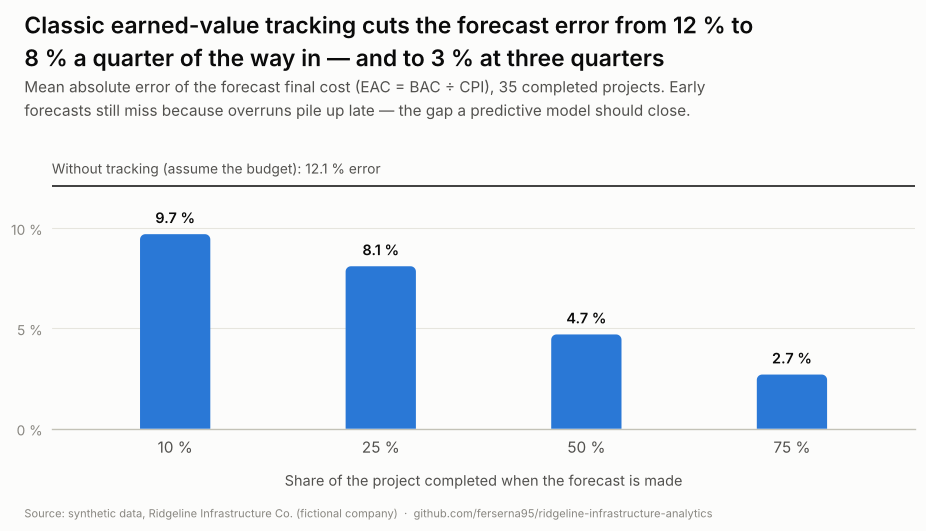

In [11]:
err = ew_summary["error_EAC_%"]
base_err = ew_summary["error_BAC_%"].iloc[0]

fig, gs = viz.new_fig(8.8, 5.0,
    f"Classic earned-value tracking cuts the forecast error from {base_err:.0f} % to {err[0.25]:.0f} % a quarter of the way in — and to {err[0.75]:.0f} % at three quarters",
    "Mean absolute error of the forecast final cost (EAC = BAC ÷ CPI), 35 completed projects. "
    "Early forecasts still miss because overruns pile up late — the gap a predictive model should close.",
    left=0.55, right=0.4, bottom=1.0)
ax = fig.add_subplot(gs[0, 0])
ax.set_xlim(-0.6, 3.6); ax.set_ylim(0, 13.0)
viz.style_axes(ax, grid="y"); ax.set_yticks([0, 5, 10])
ax.set_yticklabels(["0 %", "5 %", "10 %"])
viz.bars(ax, range(4), err.values, ACCENT, thick=46)
for i, v in enumerate(err.values):
    viz.label(ax, i, v, f"{v:.1f} %", ha="center", va="bottom", dy=5, weight="semibold")
ax.axhline(base_err, color=INK, lw=1.0, zorder=2)
viz.label(ax, -0.6, base_err, f"Without tracking (assume the budget): {base_err:.1f} % error", ha="left", va="bottom", dy=6, color=INK2, size=9)
ax.set_xticks(range(4)); ax.set_xticklabels([f"{int(a * 100)} %" for a in err.index], color=INK2, fontsize=10)
ax.set_xlabel("Share of the project completed when the forecast is made", labelpad=10)
viz.save(fig, "03_early_warning_error")

In [12]:
# Regla de alerta temprana: ¿el CPI al 25 % de avance separa a los proyectos problemáticos?
e25 = ew[ew.avance == 0.25].set_index("project_id")
print("Correlación CPI@25 % vs sobrecosto final:", round(np.corrcoef(e25.CPI, e25.overrun)[0, 1], 2))
for thr in (0.97, 0.95, 0.93):
    flag, truth = e25.CPI < thr, e25.overrun > 15
    tp, fp, fn = int((flag & truth).sum()), int((flag & ~truth).sum()), int((~flag & truth).sum())
    print(f"CPI@25% < {thr}: alerta en {int(flag.sum()):>2} | acierta {tp} | falsas alarmas {fp} | se le escapan {fn}  (de {int(truth.sum())} proyectos con sobrecosto > 15 %)")

Correlación CPI@25 % vs sobrecosto final: -0.92
CPI@25% < 0.97: alerta en 21 | acierta 14 | falsas alarmas 7 | se le escapan 0  (de 14 proyectos con sobrecosto > 15 %)
CPI@25% < 0.95: alerta en 14 | acierta 12 | falsas alarmas 2 | se le escapan 2  (de 14 proyectos con sobrecosto > 15 %)
CPI@25% < 0.93: alerta en  9 | acierta 9 | falsas alarmas 0 | se le escapan 5  (de 14 proyectos con sobrecosto > 15 %)


**Qué muestran los resultados**
- En el gráfico de trayectorias, los proyectos que terminaron con más de 20 % de sobrecosto (en azul) tienden a quedar por debajo del resto desde el 20–30 % de avance, y la separación crece hasta el final.
- Si no se hace seguimiento y se asume que el proyecto cerrará en su presupuesto, el error medio es **12.1 %**. El EVM clásico lo baja a **8.1 % al 25 % de avance, 4.7 % al 50 % y 2.7 % al 75 %**.
- Como regla simple, **CPI < 0.95 al 25 % de avance** señaló 14 proyectos: 12 de los 14 que terminaron con más de 15 % de sobrecosto, con 2 falsas alarmas y 2 que se escaparon.

**Dos advertencias**
- En estos datos el sobrecosto se acumula sobre todo hacia el final del proyecto, por eso el EAC clásico **subestima** al principio (9.7 % de error al 10 % de avance). Ese es el hueco que un modelo predictivo puede cerrar, y es el siguiente notebook.
- La correlación CPI@25 % vs. sobrecosto final (−0.92) está inflada porque las curvas de costo sintéticas son más regulares que las reales. En obras reales conviene esperar una relación más débil.

## 4. Estado de los proyectos activos

Se aplica el mismo cálculo al último dato de cada proyecto en ejecución. Regla de alerta: **roja** si CPI o SPI < 0.90, **amarilla** si < 0.95.

In [13]:
# Estado actual de los proyectos activos (tablero de alertas)
last = evm.sort_values("week").groupby("project_id").tail(1).set_index("project_id")
act = projects[projects.status == "Active"].set_index("project_id").join(
    last[["week", "pct_complete", "CPI", "SPI", "EAC"]])
act["VAC_USD_M"] = ((act.budget_at_completion - act.EAC) / 1e6).round(2)
act["alerta"] = np.where((act.CPI < .90) | (act.SPI < .90), "ROJA",
                 np.where((act.CPI < .95) | (act.SPI < .95), "AMARILLA", "VERDE"))
act["avance_%"] = (act.pct_complete * 100).round(0)
act[["name", "project_manager", "avance_%", "CPI", "SPI", "VAC_USD_M", "alerta"]].round(3)

,name,project_manager,avance_%,CPI,SPI,VAC_USD_M,alerta
project_id,,,,,,,
P007,Intersection upgrade #7,PM-04,45.0,0.941,0.744,-0.54,ROJA
P015,New bridge #15,PM-02,98.0,0.831,0.976,-7.56,ROJA
P030,Road resurfacing #30,PM-02,99.0,1.012,0.989,0.09,VERDE


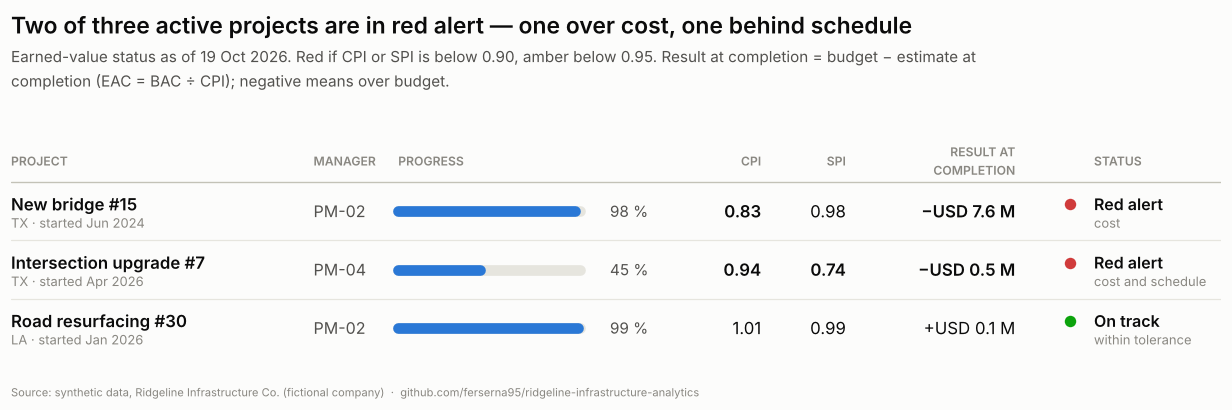

In [14]:
order = {"ROJA": 0, "AMARILLA": 1, "VERDE": 2}
label_txt = {"ROJA": "Red alert", "AMARILLA": "Amber", "VERDE": "On track"}
status_col = {"ROJA": STATUS["critical"], "AMARILLA": STATUS["warning"], "VERDE": STATUS["good"]}
board = act.reset_index()
board["o"] = board.alerta.map(order)
board = board.sort_values(["o", "VAC_USD_M"]).reset_index(drop=True)

def driver(r):
    out = []
    if r.CPI < 0.95: out.append("cost")
    if r.SPI < 0.95: out.append("schedule")
    return " and ".join(out) if out else "within tolerance"

n_red = int((board.alerta == "ROJA").sum())
fig, gs = viz.new_fig(11.6, 3.9,
    f"{['No','One','Two','Three'][n_red]} of three active projects are in red alert — one over cost, one behind schedule",
    "Earned-value status as of 19 Oct 2026. Red if CPI or SPI is below 0.90, amber below 0.95. "
    "Result at completion = budget − estimate at completion (EAC = BAC ÷ CPI); negative means over budget.",
    left=0.3, right=0.3, bottom=0.55)
ax = fig.add_subplot(gs[0, 0]); ax.axis("off")
ax.set_xlim(0, 100); ax.set_ylim(0, len(board) + 0.75)
x = dict(project=0, pm=25, bar0=32, bar1=47, pct=49.5, cpi=62, spi=69, res=83, icon=87.5, status=89.5)
hdr_y = len(board) + 0.36
def head(xv, txt, ha="left"):
    ax.text(xv, hdr_y, txt, ha=ha, va="center", fontsize=8, color=MUTED, fontweight="semibold", linespacing=1.25)
head(x["project"], "PROJECT"); head(x["pm"], "MANAGER"); head(x["bar0"], "PROGRESS")
head(x["cpi"], "CPI", "right"); head(x["spi"], "SPI", "right"); head(x["res"], "RESULT AT\nCOMPLETION", "right"); head(x["status"], "STATUS")
ax.plot([0, 100], [len(board)] * 2, color=viz.AXIS, lw=0.9)
for i, r in board.iterrows():
    y = len(board) - i - 0.5
    ax.text(x["project"], y + 0.12, r["name"], ha="left", va="center", fontsize=11, fontweight="semibold", color=INK)
    ax.text(x["project"], y - 0.2, f"{r.state} · started {r.start_date:%b %Y}", ha="left", va="center", fontsize=8.5, color=MUTED)
    ax.text(x["pm"], y, r["project_manager"], ha="left", va="center", fontsize=10.5, color=INK2)
    ax.plot([x["bar0"], x["bar1"]], [y, y], color="#e6e5de", lw=7, solid_capstyle="round", zorder=2)
    ax.plot([x["bar0"], x["bar0"] + (x["bar1"] - x["bar0"]) * min(r.pct_complete, 1)], [y, y], color=ACCENT, lw=7, solid_capstyle="round", zorder=3)
    ax.text(x["pct"], y, f"{r.pct_complete * 100:.0f} %", ha="left", va="center", fontsize=10, color=INK2)
    ax.text(x["cpi"], y, f"{r.CPI:.2f}", ha="right", va="center", fontsize=11, fontweight="semibold" if r.CPI < 0.95 else "regular")
    ax.text(x["spi"], y, f"{r.SPI:.2f}", ha="right", va="center", fontsize=11, fontweight="semibold" if r.SPI < 0.95 else "regular")
    res = r.VAC_USD_M
    ax.text(x["res"], y, f"{'−' if res < 0 else '+'}USD {abs(res):.1f} M", ha="right", va="center", fontsize=11,
            fontweight="semibold" if res < 0 else "regular")
    ax.plot([x["icon"]], [y + 0.12], marker="o", ms=9, mfc=status_col[r.alerta], mec=SURFACE, mew=1.5, ls="none")
    ax.text(x["status"], y + 0.12, label_txt[r.alerta], ha="left", va="center", fontsize=10.5, fontweight="semibold", color=INK)
    ax.text(x["status"], y - 0.2, driver(r), ha="left", va="center", fontsize=8.5, color=MUTED)
    if i < len(board) - 1:
        ax.plot([0, 100], [y - 0.5] * 2, color=viz.GRID, lw=0.8)
viz.save(fig, "08_active_projects_board")

**Dos de los tres proyectos activos están en alerta roja**, por razones distintas:
- **P015** (puente nuevo, PM-02) por **costo**: CPI 0.83, con proyección de cerrar unos **USD 7.6 M por encima de su presupuesto**. Va al 98 % de avance, así que ese sobrecosto ya es casi un hecho: ilustra por qué la alerta debe llegar al 25 %, no al 98 %.
- **P007** (intersección, PM-04) por **cronograma**: SPI 0.74 al 45 % de avance. En costo va mejor (CPI 0.94, ≈ USD 0.5 M de sobrecosto proyectado).
- **P030** está en verde.

La columna `VAC_USD_M` es la variación esperada al terminar (BAC − EAC); un valor negativo es dinero que se perdería de mantenerse el rendimiento actual.

## 5. Otros factores: órdenes de cambio y lluvia

In [15]:
# Factores asociados al sobrecosto y al atraso
rain = evm.groupby("project_id").rain_days.mean().rename("rain_per_week")
done = done.drop(columns=["rain_per_week"], errors="ignore").join(rain, on="project_id")
drivers = done[["overrun_pct", "delay_pct", "co_pct", "rain_per_week", "contract_value", "planned_weeks"]]
drivers.corr().round(2).loc[["overrun_pct", "delay_pct"]]

,overrun_pct,delay_pct,co_pct,rain_per_week,contract_value,planned_weeks
overrun_pct,1.0,0.2,0.33,0.05,0.23,0.09
delay_pct,0.2,1.0,0.50,0.04,0.58,0.76


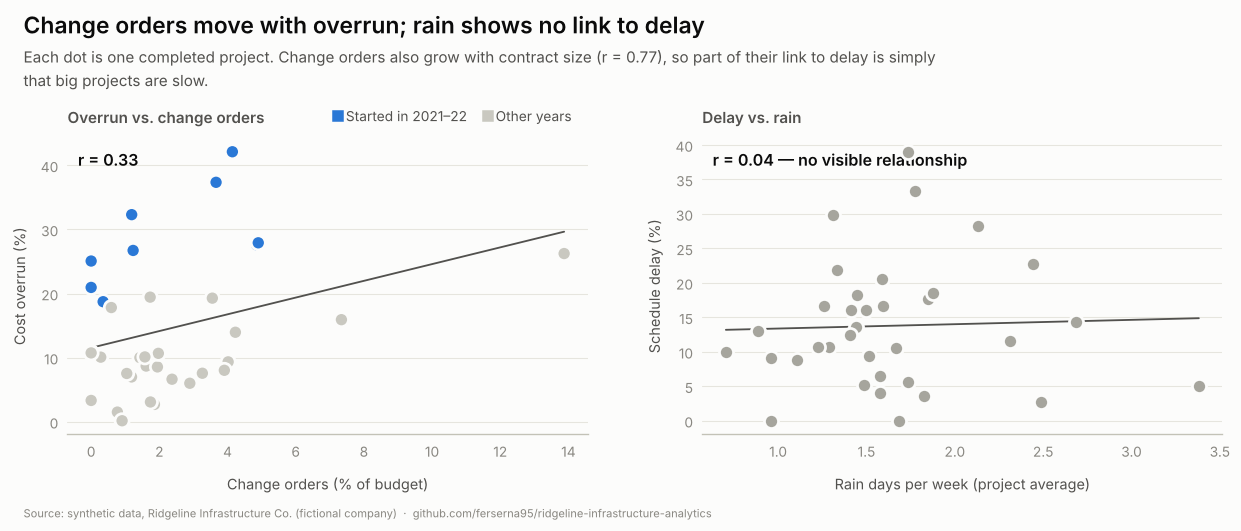

In [16]:
r_co = np.corrcoef(done.co_pct, done.overrun_pct)[0, 1]
r_rain = np.corrcoef(done.rain_per_week, done.delay_pct)[0, 1]
r_size = np.corrcoef(done.co_pct, done.contract_value)[0, 1]
crisis = done.start_year.isin([2021, 2022])

fig, gs = viz.new_fig(11.6, 5.0,
    "Change orders move with overrun; rain shows no link to delay",
    f"Each dot is one completed project. Change orders also grow with contract size (r = {r_size:.2f}), "
    "so part of their link to delay is simply that big projects are slow.",
    ncols=2, wspace=0.22, left=0.7, right=0.4, bottom=0.95)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])

def scatter_panel(ax, x, y, colors, title, xlabel, ylabel):
    viz.style_axes(ax, grid="y", panel_title=title)
    ax.scatter(x, y, s=85, c=colors, edgecolors=SURFACE, linewidths=1.8, zorder=4)
    m, b = np.polyfit(x, y, 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, m * xs + b, color=INK2, lw=1.2, zorder=3)
    ax.set_xlabel(xlabel, labelpad=10); ax.set_ylabel(ylabel, labelpad=8)

scatter_panel(ax1, done.co_pct.values, done.overrun_pct.values, np.where(crisis, ACCENT, DEEMPH),
              "Overrun vs. change orders", "Change orders (% of budget)", "Cost overrun (%)")
ax1.text(0.02, 0.96, f"r = {r_co:.2f}", transform=ax1.transAxes, fontsize=10.5, fontweight="semibold", va="top")
viz.legend_keys(ax1, [("Started in 2021–22", ACCENT), ("Other years", DEEMPH)], loc=(0.52, 1.075))
scatter_panel(ax2, done.rain_per_week.values, done.delay_pct.values, "#a6a59d",
              "Delay vs. rain", "Rain days per week (project average)", "Schedule delay (%)")
ax2.text(0.02, 0.96, f"r = {r_rain:.2f} — no visible relationship", transform=ax2.transAxes, fontsize=10.5, fontweight="semibold", va="top")
viz.save(fig, "04_change_orders_rain")

- **Órdenes de cambio:** se asocian con el sobrecosto (r = 0.33) y con el atraso (r = 0.50). Pero el monto de órdenes de cambio crece con el tamaño del contrato (r = 0.77 entre ambos), así que parte de la relación con el atraso es simplemente que los proyectos grandes tardan más. Hace falta un modelo multivariable para separarlos.
- **Lluvia:** no se detecta relación con el atraso (r ≈ 0.04). Aquí se usó el promedio de días de lluvia por semana; una versión más fina compararía la lluvia real con la esperada para esa estación y estado.

## 6. Precios ofertados vs. reales

¿El sobrecosto viene de los precios unitarios, de las cantidades o de otra cosa? Cada partida se compara entre oferta y ejecución.

In [17]:
b = bids.merge(projects[["project_id", "start_date"]], on="project_id")
b["start_year"] = b.start_date.dt.year
b["gap_pct"] = (b.actual_unit_price / b.bid_unit_price - 1) * 100
b["leak_usd"] = (b.actual_unit_price - b.bid_unit_price) * b.actual_qty      # sobrecosto atribuible a precio
b["bid_usd"] = b.bid_unit_price * b.bid_qty

gap = b.pivot_table(index="item", columns="start_year", values="gap_pct", aggfunc="mean").round(1)
leak_year = b.groupby("start_year").agg(precio_USD_M=("leak_usd", lambda s: round(s.sum() / 1e6, 2)),
                                        valor_oferta_USD_M=("bid_usd", lambda s: round(s.sum() / 1e6, 1)))
leak_year["fuga_%_de_oferta"] = (leak_year.precio_USD_M / leak_year.valor_oferta_USD_M * 100).round(1)
leak_year

,precio_USD_M,valor_oferta_USD_M,fuga_%_de_oferta
start_year,,,
2020,6.36,65.3,9.7
2021,4.82,20.6,23.4
2022,6.77,31.9,21.2
2023,1.45,36.5,4.0
2024,2.32,63.0,3.7
2025,1.88,48.2,3.9
2026,0.29,16.2,1.8


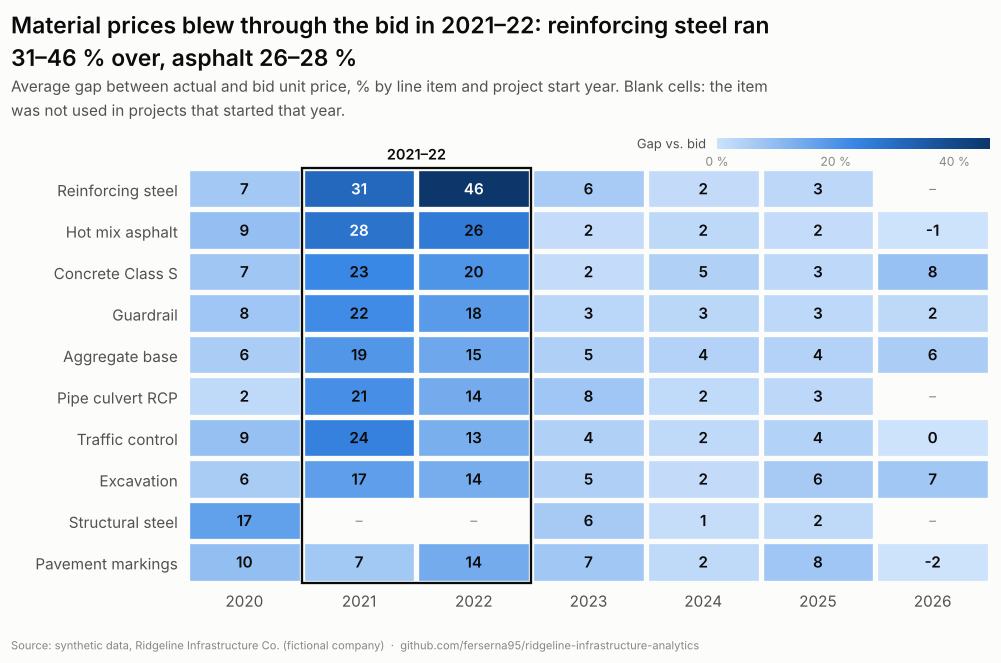

In [18]:
order = gap.mean(axis=1).sort_values(ascending=False).index
M = gap.loc[order]
vmax = 46

fig, gs = viz.new_fig(9.6, 6.2,
    "Material prices blew through the bid in 2021–22: reinforcing steel ran 31–46 % over, asphalt 26–28 %",
    "Average gap between actual and bid unit price, % by line item and project start year. "
    "Blank cells: the item was not used in projects that started that year.",
    left=1.9, right=0.4, bottom=0.8)
ax = fig.add_subplot(gs[0, 0])
ax.imshow(np.clip(M.values, 0, vmax), cmap=viz.SEQ_CMAP, vmin=0, vmax=vmax, aspect="auto")
nr, nc = M.shape
ax.set_xticks(range(nc)); ax.set_xticklabels(M.columns, color=INK2, fontsize=10)
ax.set_yticks(range(nr)); ax.set_yticklabels(M.index, color=INK2, fontsize=10)
ax.set_xticks(np.arange(-.5, nc), minor=True); ax.set_yticks(np.arange(-.5, nr), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=3.5); ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for s in ax.spines.values(): s.set_visible(False)
for i in range(nr):
    for j in range(nc):
        v = M.values[i, j]
        if np.isnan(v):
            ax.text(j, i, "–", ha="center", va="center", color=MUTED, fontsize=9)
        else:
            txt = f"{v:.0f}" if round(v) != 0 else "0"
            ax.text(j, i, txt, ha="center", va="center", fontsize=10, fontweight="semibold",
                    color="white" if v >= 27 else INK)
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((0.5, -0.5), 2, nr, fill=False, ec=INK, lw=1.5, zorder=5, clip_on=False))
ax.text(1.5, -0.62, "2021–22", ha="center", va="bottom", fontsize=9.5, fontweight="semibold", color=INK)
cax = ax.inset_axes([0.66, 1.045, 0.34, 0.028])
cax.imshow(np.linspace(0, vmax, 256)[None, :], cmap=viz.SEQ_CMAP, aspect="auto", extent=[0, vmax, 0, 1])
cax.set_yticks([]); cax.set_xticks([0, 20, 40]); cax.set_xticklabels(["0 %", "20 %", "40 %"], fontsize=8, color=MUTED)
cax.tick_params(length=0, pad=3)
for s in cax.spines.values(): s.set_visible(False)
cax.text(-0.04, 0.5, "Gap vs. bid", transform=cax.transAxes, ha="right", va="center", fontsize=8.5, color=INK2)
viz.save(fig, "05_bid_price_gap")

In [19]:
# Descomposición del sobrecosto de partidas en los 35 proyectos completados
m = bids.merge(done[["project_id", "crisis"]], on="project_id")
m["efecto_precio"]   = (m.actual_unit_price - m.bid_unit_price) * m.actual_qty
m["efecto_cantidad"] = (m.actual_qty - m.bid_qty) * m.bid_unit_price
m["valor_oferta"]    = m.bid_qty * m.bid_unit_price

dec = m.groupby("crisis")[["efecto_precio", "efecto_cantidad", "valor_oferta"]].sum() / 1e6
dec["precio_%_oferta"] = dec.efecto_precio / dec.valor_oferta * 100
dec["cantidad_%_oferta"] = dec.efecto_cantidad / dec.valor_oferta * 100
total_over = (done.final_cost.sum() - done.budget_at_completion.sum()) / 1e6
print(f"Sobrecosto total: USD {total_over:.1f} M")
print(f"  por precio:   USD {dec.efecto_precio.sum():.1f} M  ({dec.efecto_precio.sum()/total_over*100:.0f} %)")
print(f"  por cantidad: USD {dec.efecto_cantidad.sum():.1f} M  ({dec.efecto_cantidad.sum()/total_over*100:.0f} %)")
resid = total_over - dec.efecto_precio.sum() - dec.efecto_cantidad.sum()
print(f"  resto (órdenes de cambio, productividad, otros): USD {resid:.1f} M  ({resid/total_over*100:.0f} %)")
dec.round(2)

Sobrecosto total: USD 37.8 M
  por precio:   USD 21.8 M  (58 %)
  por cantidad: USD 6.3 M  (17 %)
  resto (órdenes de cambio, productividad, otros): USD 9.7 M  (26 %)


,efecto_precio,efecto_cantidad,valor_oferta,precio_%_oferta,cantidad_%_oferta
crisis,,,,,
2021–22,11.59,1.60,52.56,22.06,3.04
otros años,10.22,4.72,175.79,5.81,2.69


**Qué muestran los resultados**
- En **2021–2022 la brecha de precio fue enorme**: el acero de refuerzo costó **31 % y 46 % más** de lo ofertado, y la mezcla asfáltica **28 % y 26 %**. Casi todas las demás partidas se movieron entre 13 y 24 %. Desde 2023 la brecha baja a 1–8 %. (El acero estructural no aparece en esos años porque no hubo puentes en ejecución.)
- Para los proyectos de 2021–22, el efecto precio fue **22 % del valor ofertado**, frente a 5.8 % en el resto.
- Del sobrecosto total de los 35 proyectos (USD 37.8 M), **el precio explica ~58 %**, las cantidades ~17 % y el resto (~26 %: órdenes de cambio, productividad y otros) no se explica por partidas.

La causa se ofertó con los precios del año anterior en un mercado con inflación: un buen candidato para una **regla de ajuste de precios y reserva de contingencia por partida** al ofertar.

## 7. Flota: ralentí y firma de falla

In [20]:
tele["idle_ratio"] = tele.idle_hours / tele.engine_hours.where(tele.engine_hours > 0)
fleet = tele.groupby(["equipment_id", "equipment_type"]).agg(
    horas_motor=("engine_hours", "sum"), horas_ralenti=("idle_hours", "sum"), litros=("fuel_liters", "sum")).reset_index()
fleet["ralenti_%"] = (fleet.horas_ralenti / fleet.horas_motor * 100).round(1)
baseline = fleet["ralenti_%"].median()

# litros por hora de ralentí y por hora de trabajo, estimados con mínimos cuadrados por tipo de equipo
coef = {}
for kind, g in tele[tele.engine_hours > 0].groupby("equipment_type"):
    X = np.column_stack([g.engine_hours - g.idle_hours, g.idle_hours])
    coef[kind] = np.linalg.lstsq(X, g.fuel_liters.values, rcond=None)[0]
fleet["L_por_h_ralenti"] = fleet.equipment_type.map(lambda k: coef[k][1])
fleet["exceso_ralenti_h"] = (fleet.horas_ralenti - fleet.horas_motor * baseline / 100).clip(lower=0)
fleet["exceso_litros"] = fleet.exceso_ralenti_h * fleet.L_por_h_ralenti
print(f"Ralentí mediano de la flota: {baseline:.1f} %")
top = fleet.sort_values("ralenti_%", ascending=False).head(5)
top[["equipment_id", "equipment_type", "ralenti_%", "exceso_ralenti_h", "exceso_litros"]].round(0)

Ralentí mediano de la flota: 22.1 %


,equipment_id,equipment_type,ralenti_%,exceso_ralenti_h,exceso_litros
13,EXC-02,Excavator,52.0,1246.0,7767.0
3,DOZ-01,Dozer,52.0,1214.0,9378.0
9,DUM-04,Dump truck,52.0,1192.0,6661.0
0,CRA-01,Crane,22.0,9.0,45.0
5,DOZ-03,Dozer,22.0,8.0,64.0


Exceso de ralentí de las 3 máquinas problemáticas: 3,708 h  ≈ 24,122 L de combustible


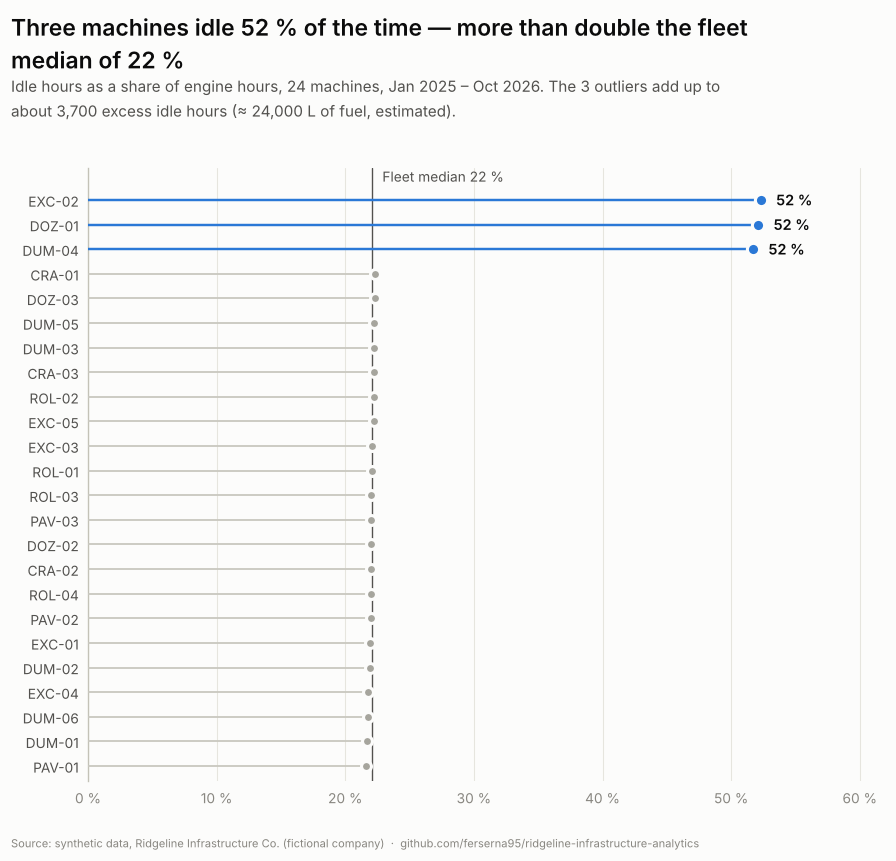

In [21]:
tot_l = fleet.exceso_litros.sum(); tot_h = fleet.exceso_ralenti_h.sum()
fl = fleet.sort_values("ralenti_%", ascending=False).reset_index(drop=True)
top_n = int((fl["ralenti_%"] > 40).sum())
top_v = fl["ralenti_%"].head(top_n).mean()

fig, gs = viz.new_fig(8.8, 8.0,
    f"{['Zero','One','Two','Three','Four'][top_n]} machines idle {top_v:.0f} % of the time — more than double the fleet median of {baseline:.0f} %",
    f"Idle hours as a share of engine hours, 24 machines, Jan 2025 – Oct 2026. The {top_n} outliers add up to about "
    f"{round(tot_h, -2):,.0f} excess idle hours (≈ {round(tot_l, -3):,.0f} L of fuel, estimated).",
    left=1.0, right=0.55, bottom=0.8)
ax = fig.add_subplot(gs[0, 0])
ax.set_xlim(0, 62); ax.set_ylim(len(fl) - 0.4, -1.3)
viz.style_axes(ax, grid="x", baseline="left")
for i, row in fl.iterrows():
    hi = row["ralenti_%"] > 40
    ax.plot([0, row["ralenti_%"]], [i, i], color=ACCENT if hi else DEEMPH, lw=1.6 if hi else 1.2, zorder=3)
    viz.dot(ax, row["ralenti_%"], i, ACCENT if hi else "#a6a59d", size=8 if hi else 6.5)
    if hi:
        viz.label(ax, row["ralenti_%"], i, f"{row['ralenti_%']:.0f} %", dx=10, weight="semibold")
ax.set_yticks(range(len(fl))); ax.set_yticklabels(fl.equipment_id, color=INK2, fontsize=9)
ax.set_xticks([0, 10, 20, 30, 40, 50, 60]); ax.set_xticklabels([f"{t} %" for t in (0, 10, 20, 30, 40, 50, 60)])
ax.axvline(baseline, color=INK2, lw=0.9, zorder=2)
viz.label(ax, baseline, -0.95, f"Fleet median {baseline:.0f} %", ha="left", va="center", dx=7, size=9, color=INK2)
viz.save(fig, "06_idle_by_machine")
print(f"Exceso de ralentí de las {top_n} máquinas problemáticas: {tot_h:,.0f} h  ≈ {tot_l:,.0f} L de combustible")

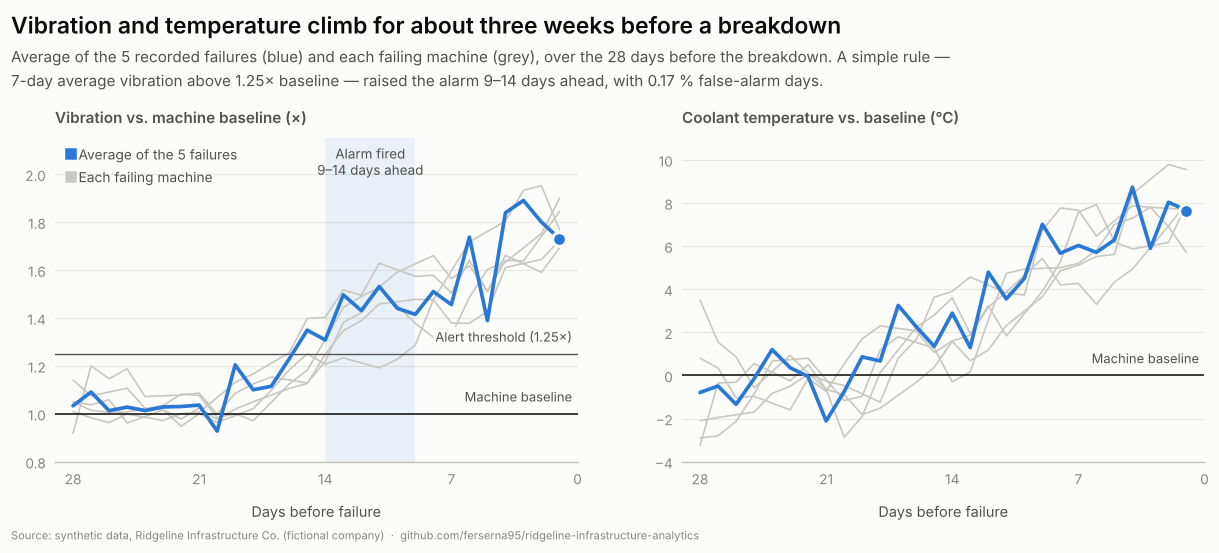

In [22]:
# Firma de falla: vibración y temperatura de cada máquina respecto a su propia línea base, en los 28 días previos
sig = []
for _, f in fails.iterrows():
    e = tele[tele.equipment_id == f.equipment_id].copy()
    base_v = e[e.date < f.failure_date - pd.Timedelta(days=45)].vibration_rms.median()
    base_t = e[e.date < f.failure_date - pd.Timedelta(days=45)].coolant_temp_max_c.median()
    e["dias_antes"] = (f.failure_date - e.date).dt.days
    e = e[(e.dias_antes > 0) & (e.dias_antes <= 28)]
    sig.append(pd.DataFrame({"equipment_id": f.equipment_id, "dias_antes": e.dias_antes,
                             "vib_ratio": e.vibration_rms / base_v, "temp_delta": e.coolant_temp_max_c - base_t}))
sig = pd.concat(sig)
avg = sig.groupby("dias_antes")[["vib_ratio", "temp_delta"]].mean()

fig, gs = viz.new_fig(11.6, 5.2,
    "Vibration and temperature climb for about three weeks before a breakdown",
    "Average of the 5 recorded failures (blue) and each failing machine (grey), over the 28 days before the breakdown. "
    "A simple rule — 7-day average vibration above 1.25× baseline — raised the alarm 9–14 days ahead, with 0.17 % false-alarm days.",
    ncols=2, wspace=0.2, left=0.7, right=0.45, bottom=0.9)
ax1, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
for ax, col, title, ylim in ((ax1, "vib_ratio", "Vibration vs. machine baseline (×)", (0.8, 2.15)),
                              (ax2, "temp_delta", "Coolant temperature vs. baseline (°C)", (-4, 11))):
    ax.set_xlim(29, 0); ax.set_ylim(*ylim)
    viz.style_axes(ax, grid="y", panel_title=title)
    for eid, g in sig.groupby("equipment_id"):
        ax.plot(g.dias_antes, g[col].rolling(3, min_periods=1).mean(), color=DEEMPH, lw=1.1, zorder=2)
    ax.plot(avg.index, avg[col], color=ACCENT, lw=2.4, zorder=4)
    viz.dot(ax, 1, avg[col].iloc[0], ACCENT, size=9)
    ax.set_xticks([28, 21, 14, 7, 0]); ax.set_xticklabels(["28", "21", "14", "7", "0"])
    ax.set_xlabel("Days before failure", labelpad=10)
ax1.axvspan(9, 14, color=ACCENT, alpha=0.09, lw=0, zorder=1)
viz.label(ax1, 11.5, 2.12, "Alarm fired\n9–14 days ahead", ha="center", va="top", size=8.8, color=INK2)
viz.hline(ax1, 1.0, "Machine baseline", x_text=0.3, ha="right", size=8.5)
viz.hline(ax1, 1.25, "Alert threshold (1.25×)", color=INK2, x_text=0.3, ha="right", size=8.5, lw=0.9)
viz.hline(ax2, 0.0, "Machine baseline", x_text=0.3, ha="right", size=8.5)
viz.legend_keys(ax1, [("Average of the 5 failures", ACCENT)], loc=(0.03, 0.95))
viz.legend_keys(ax1, [("Each failing machine", DEEMPH)], loc=(0.03, 0.88))
viz.save(fig, "07_failure_signature")

In [23]:
# Regla simple de mantenimiento predictivo: media móvil 7 d de vibración > 1.25 × línea base de la máquina
tele = tele.sort_values(["equipment_id", "date"]).copy()
base60 = tele.groupby("equipment_id").apply(lambda g: g.vibration_rms.iloc[:60].median(), include_groups=False)
tele["vib_ratio"] = tele.vibration_rms / tele.equipment_id.map(base60)
tele["vib7"] = tele.groupby("equipment_id").vib_ratio.transform(lambda s: s.rolling(7, min_periods=7).mean())
tele["alerta"] = tele.vib7 > 1.25

res, pre_window = [], pd.Series(False, index=tele.index)
for _, f in fails.iterrows():
    m = (tele.equipment_id == f.equipment_id) & (tele.date >= f.failure_date - pd.Timedelta(days=28)) & (tele.date < f.failure_date)
    pre_window |= m
    first = tele[m & tele.alerta].date.min()
    res.append(dict(equipo=f.equipment_id, falla=f.failure_date.date(), primera_alerta=None if pd.isna(first) else first.date(),
                    dias_de_anticipacion=None if pd.isna(first) else (f.failure_date - first).days))
healthy_days = tele[~pre_window & tele.vib7.notna()]
print(f"Falsas alarmas: {int(healthy_days.alerta.sum())} de {len(healthy_days):,} equipo-día fuera de ventanas de falla "
      f"({healthy_days.alerta.mean()*100:.2f} %)")
pd.DataFrame(res)

Falsas alarmas: 22 de 13,218 equipo-día fuera de ventanas de falla (0.17 %)


,equipo,falla,primera_alerta,dias_de_anticipacion
0,EXC-03,2025-09-12,2025-09-03,9
1,PAV-02,2026-01-20,2026-01-08,12
2,ROL-03,2026-09-02,2026-08-19,14
3,CRA-01,2026-04-08,2026-03-28,11
4,DUM-02,2026-07-15,2026-07-03,12


**Qué muestran los resultados**
- **Ralentí:** tres máquinas (EXC-02, DOZ-01, DUM-04) pasan **52 %** de sus horas de motor en ralentí, contra una mediana de la flota de **22 %**. En los ~22 meses de datos acumulan **~3,700 horas de ralentí por encima de la norma** y ~24,000 L de combustible estimados. El valor de las horas depende de la tarifa horaria del equipo, que el cliente debe aportar.
- **Falla previa:** en las 5 averías, la vibración y la temperatura del refrigerante suben durante las ~3 semanas anteriores. Una regla simple (vibración promedio de 7 días > 1.25 × la línea base de la máquina) avisó **entre 9 y 14 días antes** de cada falla, con 22 falsas alarmas de 13,218 equipo-días (0.17 %).
- **Límite:** con solo 5 fallas, el umbral se define y se evalúa con los mismos eventos. No se puede estimar cómo generalizaría. Es un punto de partida para un modelo con validación, no un resultado.

## 8. Hallazgos y siguientes pasos

| # | Hallazgo | Solidez |
|---|---|---|
| 1 | Las obras de **2021–22 terminaron con ~29 % de sobrecosto** (vs. ~10 %); el **precio de los materiales explica ~58 %** del sobrecosto total del portafolio | **Alta**: 9 vs. 26 proyectos, consistente entre gerentes |
| 2 | El **CPI al 25 % de avance** anticipa el sobrecosto final; el EVM clásico baja el error de 12 % a 8 % (25 %) y 3 % (75 %) | Media: las curvas sintéticas son más limpias que las reales |
| 3 | **P015 y P007** están en alerta roja; P015 proyecta ~USD 7.6 M de sobrecosto | Alta (cálculo directo) |
| 4 | PM-02 supera a PM-01 y PM-03 incluso fuera de 2021–22 (12.3 % vs. 7.7 % y 6.1 %) | Media: pocos proyectos por gerente |
| 5 | Tres máquinas operan con **52 % de ralentí** frente a 22 % de la flota | Alta |
| 6 | Las fallas se anuncian **9–14 días antes** con vibración y temperatura | Baja: solo 5 eventos |
| 7 | Tipo de obra (puentes), PM-04 y lluvia | **No concluyente**: muestra insuficiente o sin relación detectada |

**Limitaciones:** datos sintéticos; 35 proyectos completados; el análisis es descriptivo y las asociaciones no prueban causalidad.

**Siguiente notebook (`02_modelo_predictivo`):** modelo que prediga el sobrecosto final desde etapas tempranas (CPI, SPI, órdenes de cambio, tipo, año), validado proyecto por proyecto (leave-one-out), y comparación contra el EAC clásico.